In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Cleaning Data 

## Weather and AQ Data

In [2]:
weather_df = pd.read_csv("../raw/weather.csv")
weather_df

,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,2024-01-01 00:00:00,22.8,19,28.0,0.2,NaN,NaN,10.7,NaN,1016.8,NaN
1,2024-01-02 00:00:00,23.4,21,27.0,0.1,NaN,NaN,11.7,NaN,1016.0,NaN
2,2024-01-03 00:00:00,19.5,17,22.0,9.7,NaN,NaN,13.0,NaN,1019.9,NaN
3,2024-01-04 00:00:00,19.1,17,21.0,0.0,NaN,NaN,8.8,NaN,1019.0,NaN
4,2024-01-05 00:00:00,20.2,18,23.0,0.0,NaN,NaN,6.5,NaN,1017.6,NaN
...,...,...,...,...,...,...,...,...,...,...,...
361,2024-12-27 00:00:00,18.4,17,20.0,0.0,NaN,NaN,14.4,NaN,1024.2,NaN
362,2024-12-28 00:00:00,18.8,15,23.0,0.0,NaN,NaN,12.3,NaN,1025.9,NaN
363,2024-12-29 00:00:00,18.0,14,22.0,0.0,NaN,NaN,10.7,NaN,1021.5,NaN
364,2024-12-30 00:00:00,17.6,13,21.0,0.0,NaN,NaN,7.3,NaN,1020.6,NaN


In [3]:
aq_df = pd.read_csv("../raw/air_quality.csv")
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),methane (μg/m³)
0,2024-01-01T00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,0.0,0.0,NaN
1,2024-01-01T01:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,0.0,0.0,NaN
2,2024-01-01T02:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,0.0,0.0,NaN
3,2024-01-01T03:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,0.0,0.0,NaN
4,2024-01-01T04:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31T19:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,0.0,0.0,1747.0
8780,2024-12-31T20:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,0.0,0.0,1766.0
8781,2024-12-31T21:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,0.0,0.0,1765.0
8782,2024-12-31T22:00,112.9,112.7,43.0,51.4,38.1,477.0,1365.0,0.0,0.64,0.0,0.0,1765.0


In [4]:
weather_df["date"] = pd.to_datetime(weather_df["date"], errors="coerce")
aq_df["time"] = pd.to_datetime(aq_df["time"], errors="coerce")

## Creating QA and deleted flag column

In [5]:
qa_logs = []
def qa_log(dataset, rule, count, total):
    qa_logs.append({
        "dataset": dataset,
        "rule": rule,
        "count": int(count),
        "total": int(total),
        "percent": round(100 * count / total, 4) if total else np.nan
    })

In [6]:
weather_df["is_deleted_wt"] = False
aq_df["is_deleted_aq"] = False

## Handle missing data

### Weather

In [7]:
for c in weather_df.columns:
    mask = weather_df[c].isna()
    qa_log("weather", f"Weather Missing {c}", mask.sum(), len(weather_df))

In [8]:
weather_df.isna().sum()

date               0
tavg               0
tmin               0
tmax               0
prcp              12
snow             366
wdir             366
wspd               0
wpgt             366
pres               0
tsun             366
is_deleted_wt      0
dtype: int64

"snow", "wdir", "wpgt", "tsun" missing 100% -> drop columns 

"prcp" missing 12/366 -> analyze data first

In [9]:
drop_cols = ["snow", "wdir", "wpgt", "tsun"]
weather_df = weather_df.drop(columns=drop_cols)

<Axes: xlabel='date'>

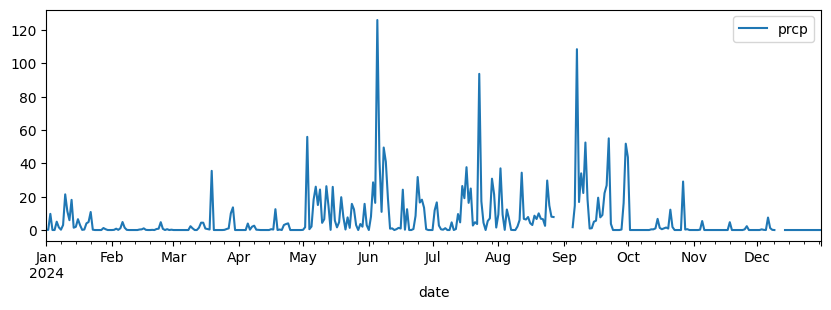

In [10]:
weather_df.plot(kind="line", x="date", y="prcp", figsize=(10,3))

<Axes: xlabel='date'>

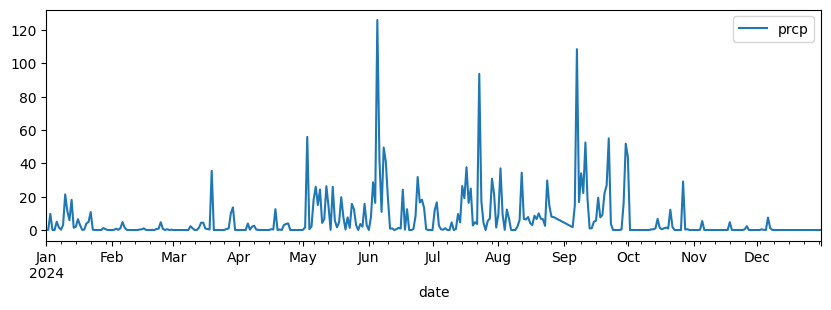

In [11]:
weather_df["prcp"] = weather_df["prcp"].interpolate(method="linear")
weather_df.plot(kind="line", x="date", y="prcp", figsize=(10,3))

### Air Quality

In [12]:
for c in aq_df.columns:
    mask = aq_df[c].isna()
    qa_log("air_quality", f"AQ Missing {c}", mask.sum(), len(aq_df))

In [13]:
print(aq_df.shape[0])
aq_df.isna().sum()

8784


time                           0
pm10 (μg/m³)                   0
pm2_5 (μg/m³)                  0
ozone (μg/m³)                  0
sulphur_dioxide (μg/m³)        0
nitrogen_dioxide (μg/m³)       0
carbon_dioxide (ppm)        7183
carbon_monoxide (μg/m³)        0
uv_index ()                    0
aerosol_optical_depth ()       0
dust (μg/m³)                   0
uv_index_clear_sky ()          0
methane (μg/m³)             7183
is_deleted_aq                  0
dtype: int64

"carbon_dioxide" and "methane" are missing 7183/8784 (81.77%) -> drop columns

In [14]:
drop_cols = ["carbon_dioxide (ppm)", "methane (μg/m³)"]
aq_df = aq_df.drop(columns=drop_cols)
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


## Check negative values

In [15]:
weather_df

,date,tavg,tmin,tmax,prcp,wspd,pres,is_deleted_wt
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,False
...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,False


In [16]:
check_weather_neg_cols = ["prcp", "wspd", "pres"]
for col in check_weather_neg_cols:
    mask = weather_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    weather_df["is_deleted_wt"] = weather_df["is_deleted_wt"] | mask
    qa_log("weather", f"Weather negative {col}", mask.sum(), len(weather_df))

In [17]:
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


In [18]:
check_aq_neg_cols = aq_df.columns.drop("time").tolist()
for col in check_aq_neg_cols:
    mask = aq_df[col].apply(lambda x: False if pd.isna(x) else x < 0)
    aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | mask
    qa_log("air_quality", f"AQ {col}", mask.sum(), len(aq_df))

## Check if PM2.5 > PM10

In [19]:
mask = (aq_df["pm2_5 (μg/m³)"] > aq_df["pm10 (μg/m³)"])
aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | mask
qa_log("air_quality", "PM2.5 > PM10", mask.sum(), len(aq_df))

## Check if there are duplicated timestamp

In [20]:
dup_weather_mask = weather_df.duplicated("date", keep=False)
weather_df["is_deleted_wt"] = weather_df["is_deleted_wt"] | dup_weather_mask
qa_log("weather", "Weather duplicate timestamps", dup_weather_mask.sum(), len(weather_df))

In [21]:
dup_aq_mask = aq_df.duplicated("time", keep=False)
aq_df["is_deleted_aq"] = aq_df["is_deleted_aq"] | dup_aq_mask
qa_log("air_quality", "AQ duplicate timestamps", dup_aq_mask.sum(), len(aq_df))

## Check if there are missing timestamps

In [22]:
start = weather_df["date"].min()
end = weather_df["date"].max()
ts = pd.date_range(start=start, end=end, freq="d")
weather_missing_ts = len(ts) - weather_df["date"].nunique()
qa_log("weather", "Weather missing timestamps", weather_missing_ts, len(ts))

weather_missing_ts

0

In [23]:
start = aq_df["time"].min()
end = aq_df["time"].max()
ts = pd.date_range(start=start, end=end, freq="h")
aq_missing_ts = len(ts) - aq_df["time"].nunique()
qa_log("air_quality", "AQ missing timestamps", aq_missing_ts, len(ts))

aq_missing_ts

0

In [24]:
weather_df

,date,tavg,tmin,tmax,prcp,wspd,pres,is_deleted_wt
0,2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,False
1,2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,False
2,2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,False
3,2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,False
4,2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,False
...,...,...,...,...,...,...,...,...
361,2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,False
362,2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,False
363,2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,False
364,2024-12-30,17.6,13,21.0,0.0,7.3,1020.6,False


In [25]:
aq_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,702.0,0.0,0.46,0.0,0.0,False
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,716.0,0.0,0.48,0.0,0.0,False
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,732.0,0.0,0.52,0.0,0.0,False
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,754.0,0.0,0.52,0.0,0.0,False
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,778.0,0.0,0.51,0.0,0.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,1998.0,0.0,0.71,0.0,0.0,False
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,1915.0,0.0,0.69,0.0,0.0,False
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,1618.0,0.0,0.66,0.0,0.0,False
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,1365.0,0.0,0.64,0.0,0.0,False


## Resample hourly -> daily in AQ

In [26]:
aq_df = aq_df.set_index("time").sort_index()

In [27]:
aq_num_cols = aq_df.select_dtypes(include=[np.number]).columns.tolist()
agg_map = {c: "mean" for c in aq_num_cols}
agg_map["is_deleted_aq"] = "max"

masked = aq_df.copy()
masked.loc[masked['is_deleted_aq'], aq_num_cols] = np.nan

aq_daily_df = masked.resample('D').agg(agg_map)
aq_daily_df = aq_daily_df.round(2)

In [28]:
aq_daily_df

,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted_aq
time,,,,,,,,,,,
2024-01-01,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


## Merge 2 datas

In [29]:
weather_df = weather_df.set_index("date").sort_index()

In [30]:
clean_df = pd.merge(weather_df, aq_daily_df, left_index=True, right_index=True)
clean_df["is_deleted"] = clean_df["is_deleted_aq"] | clean_df["is_deleted_wt"]
clean_df = clean_df.drop(columns=["is_deleted_aq", "is_deleted_wt"])
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


In [31]:
processed_dir = Path("../processed")
reports_dir = Path("../reports")

clean_df.to_csv(processed_dir / "final_data.csv", index=True)
qa_df = pd.DataFrame(qa_logs)
qa_df.to_csv(reports_dir / "qa_summary.csv", index=False)

In [32]:
qa_df

,dataset,rule,count,total,percent
0,weather,Weather Missing date,0,366,0.0000
1,weather,Weather Missing tavg,0,366,0.0000
2,weather,Weather Missing tmin,0,366,0.0000
3,weather,Weather Missing tmax,0,366,0.0000
4,weather,Weather Missing prcp,12,366,3.2787
5,weather,Weather Missing snow,366,366,100.0000
6,weather,Weather Missing wdir,366,366,100.0000
7,weather,Weather Missing wspd,0,366,0.0000
8,weather,Weather Missing wpgt,366,366,100.0000
9,weather,Weather Missing pres,0,366,0.0000


In [33]:
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


In [34]:
qa_summary = pd.read_csv("../reports/qa_summary_final.csv")
qa_summary

,dataset,rule,count,total,percent,decision
0,weather,Weather Missing date,0,366,0.0000,NaN
1,weather,Weather Missing tavg,0,366,0.0000,NaN
2,weather,Weather Missing tmin,0,366,0.0000,NaN
3,weather,Weather Missing tmax,0,366,0.0000,NaN
4,weather,Weather Missing prcp,12,366,3.2787,Fill NA by using interpolation
5,weather,Weather Missing snow,366,366,100.0000,Drop column
6,weather,Weather Missing wdir,366,366,100.0000,Drop column
7,weather,Weather Missing wspd,0,366,0.0000,NaN
8,weather,Weather Missing wpgt,366,366,100.0000,Drop column
9,weather,Weather Missing pres,0,366,0.0000,NaN


# Summary & Statistics

In [35]:
daily_stats_series = pd.Series({
    "temp_mean": clean_df["tavg"].mean(),
    "temp_p50": clean_df["tavg"].quantile(0.5),
    "temp_p95": clean_df["tavg"].quantile(0.95),

    "prcp_sum": clean_df["prcp"].sum(),
    "prcp_days_than_1mm": (clean_df["prcp"] >= 1).sum(),

    "wspd_mean": clean_df["wspd"].mean(),
    "pres_mean": clean_df["pres"].mean(),

    "pm25_p95": clean_df["pm2_5 (μg/m³)"].quantile(0.95),
    "pm10_p95": clean_df["pm10 (μg/m³)"].quantile(0.95),
    "pm25_exceed_days": (clean_df["pm2_5 (μg/m³)"] > 5).sum(),
    "pm10_exceed_days": (clean_df["pm10 (μg/m³)"] > 15).sum(),

    "uv_max_daily_mean": clean_df["uv_index ()"].mean()
    
}).round(2)

In [36]:
daily_stats = daily_stats_series.reset_index()
daily_stats.columns = ["criteria", "value"]

In [37]:
daily_stats

,criteria,value
0,temp_mean,25.16
1,temp_p50,26.70
2,temp_p95,31.40
3,prcp_sum,2306.20
4,prcp_days_than_1mm,169.00
5,wspd_mean,10.35
6,pres_mean,1010.67
7,pm25_p95,83.02
8,pm10_p95,112.82
9,pm25_exceed_days,366.00


In [38]:
daily_stats.to_csv(processed_dir / "daily_weather_aqi_21.0167_105.8_2024.csv", index=False)

In [39]:
stats = pd.read_csv("../processed/daily_weather_aqi_21.0167_105.8_2024_final.csv")
stats

,criteria,value,unit of measurement,formula
0,temp_mean,25.16,oC,mean
1,temp_p50,26.70,oC,quantile
2,temp_p95,31.40,oC,quantile
3,prcp_sum,2306.20,mm,sum
4,prcp_days_than_1mm,169.00,day,count
5,wspd_mean,10.35,km/h,mean
6,pres_mean,1010.67,hPa,mean
7,pm25_p95,83.02,μg/m³,quantile
8,pm10_p95,112.82,μg/m³,quantile
9,pm25_exceed_days,366.00,day,count


# Visualization

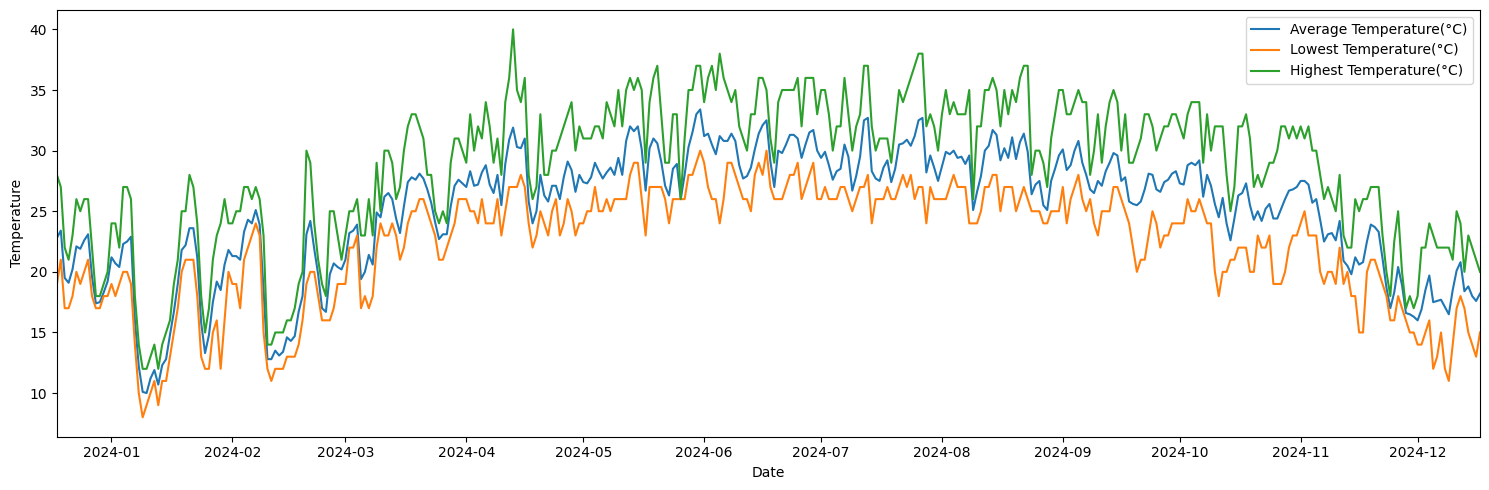

In [40]:
plt.figure(figsize=(15, 5))
plt.plot(clean_df.index, clean_df["tavg"], label="Average Temperature(°C)")
plt.plot(clean_df.index, clean_df['tmin'], label='Lowest Temperature(°C)')
plt.plot(clean_df.index, clean_df['tmax'], label='Highest Temperature(°C)')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=15))
plt.xlim(clean_df.index.min(), clean_df.index.max())
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/Temperature_Daily.png')

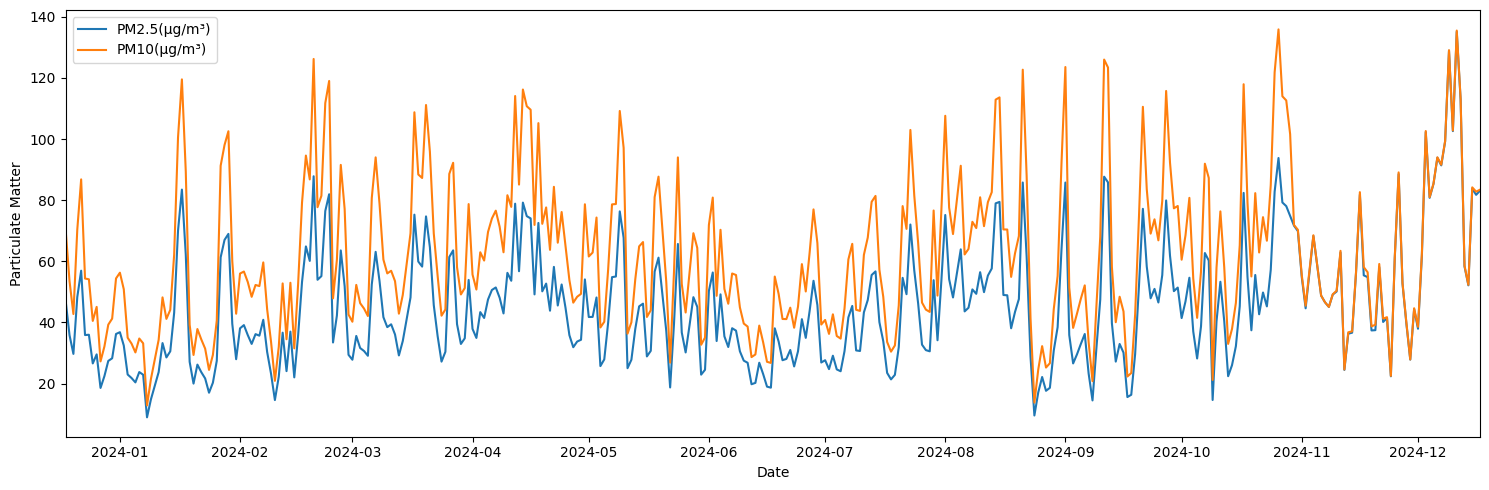

In [41]:
plt.figure(figsize=(15, 5))
plt.plot(clean_df.index, clean_df["pm2_5 (μg/m³)"], label="PM2.5(μg/m³)")
plt.plot(clean_df.index, clean_df['pm10 (μg/m³)'], label='PM10(μg/m³)')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=15))
plt.xlim(clean_df.index.min(), clean_df.index.max())
plt.xlabel('Date')
plt.ylabel('Particulate Matter')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/Particulate_Matter_Daily.png')

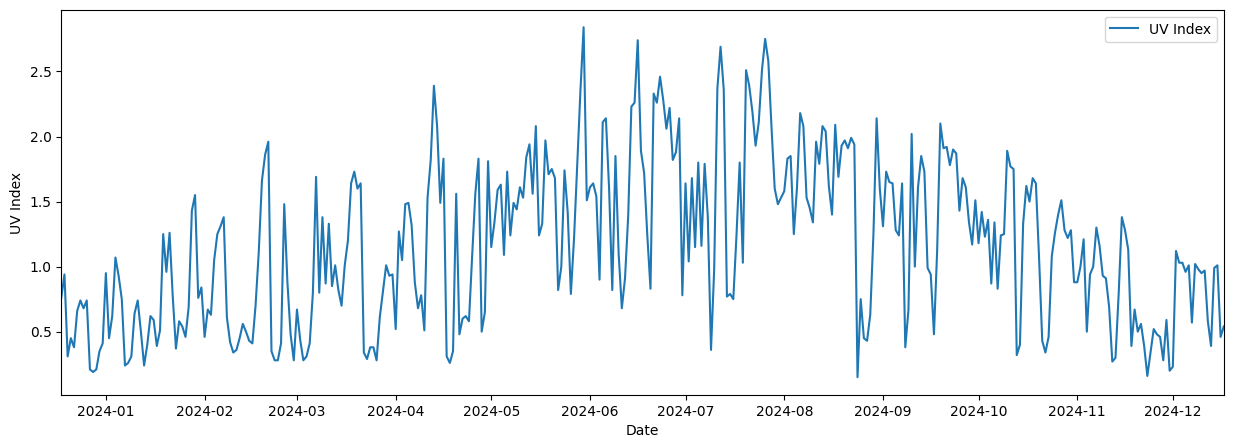

In [42]:
plt.figure(figsize=(15, 5))
plt.plot(clean_df.index, clean_df["uv_index ()"], label="UV Index")
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonthday=15))
plt.xlim(clean_df.index.min(), clean_df.index.max())
plt.xlabel('Date')
plt.ylabel('UV Index')
plt.legend()
plt.savefig('../figures/UV_Index_Daily.png')

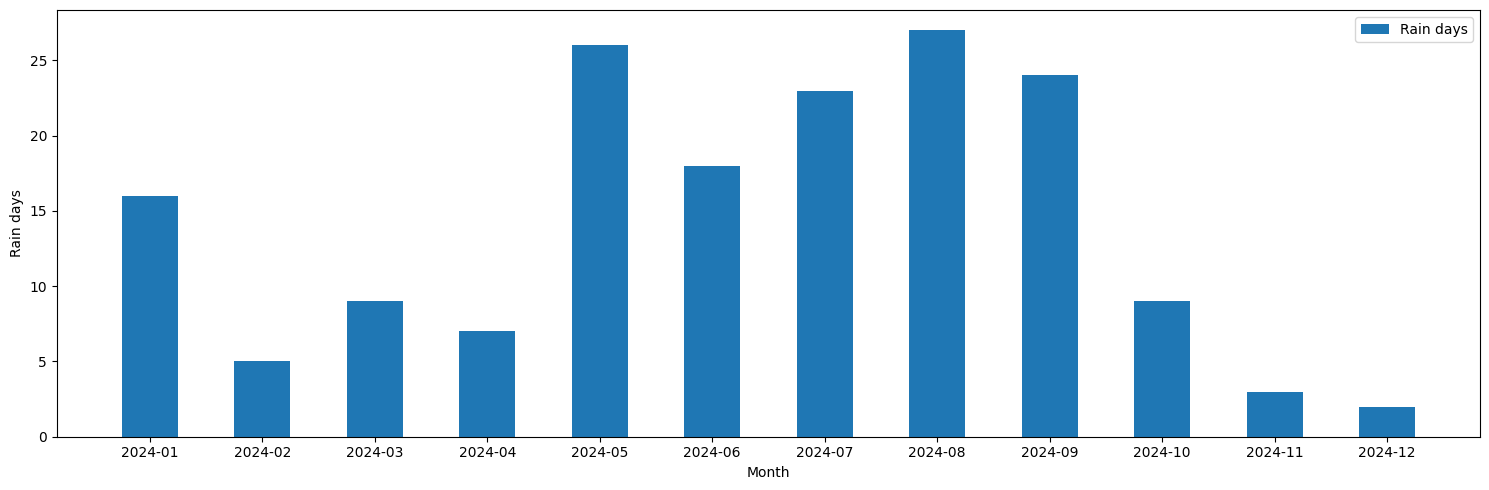

In [43]:
daily_rain = clean_df['prcp'].resample('D').sum()
rain_days = (daily_rain >= 1).resample('ME').sum()
plt.figure(figsize=(15, 5))
x_labels = rain_days.index.strftime('%Y-%m')
plt.bar(x_labels, rain_days.values, label='Rain days', width=0.5)
plt.xlabel('Month')
plt.ylabel('Rain days')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/Rain_Days_Per_Month.png')

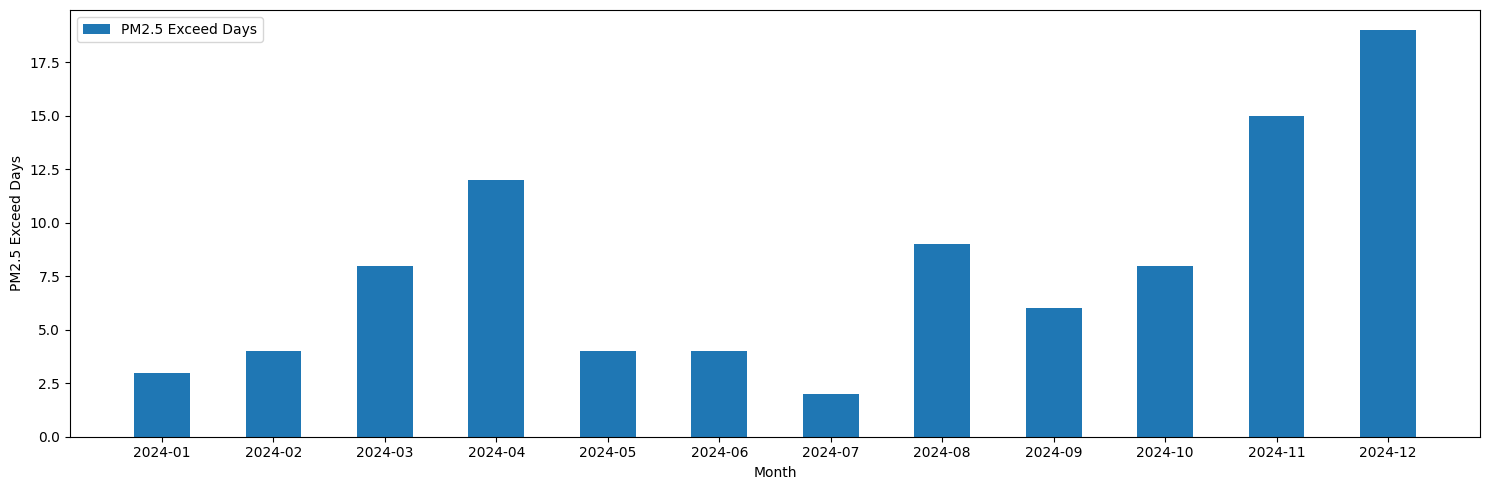

In [44]:
daily_pm25 = clean_df['pm2_5 (μg/m³)'].resample('D').mean()
pm25_exceed = (daily_pm25 > 55.4).resample('ME').sum()
plt.figure(figsize=(15, 5))
x_label = pm25_exceed.index.strftime('%Y-%m')
plt.bar(x_label, pm25_exceed.values, label='PM2.5 Exceed Days', width=0.5)
plt.xlabel('Month')
plt.ylabel('PM2.5 Exceed Days')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/PM2.5_Exceed_Days.png')